In [1]:
!pip install gymnasium

   ---------------------------------------- 0.0/953.9 kB ? eta -:--:--
   -------------------------------- ------- 786.4/953.9 kB 8.0 MB/s eta 0:00:01
   ---------------------------------------- 953.9/953.9 kB 7.5 MB/s  0:00:00

   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   ---------------------------------------- 2/2 [gymnasium]



In [2]:
import gymnasium as gym

print("Gymnasium installed successfully!")
print("Gymnasium Version:", gym.__version__)

Gymnasium installed successfully!
Gymnasium Version: 1.3.0


In [3]:
import gymnasium as gym

env = gym.make("CartPole-v1")

observation, info = env.reset()

print("Initial Observation:")
print(observation)

print("Environment created successfully!")

env.close()

Initial Observation:
[ 0.03369901 -0.00745252 -0.00381497 -0.04232543]
Environment created successfully!


In [4]:
import gymnasium as gym

env = gym.make("CartPole-v1")

print("Observation Space:")
print(env.observation_space)

print("\nAction Space:")
print(env.action_space)

env.close()

Observation Space:
Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)

Action Space:
Discrete(2)


In [5]:
import gymnasium as gym

env = gym.make("FrozenLake-v1", is_slippery=False)

state, info = env.reset()

print("Initial State:", state)

action = env.action_space.sample()
next_state, reward, terminated, truncated, info = env.step(action)

print("Action:", action)
print("Next State:", next_state)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

env.close()

Initial State: 0
Action: 3
Next State: 0
Reward: 0
Terminated: False
Truncated: False


In [6]:
import gymnasium as gym

env = gym.make("FrozenLake-v1", is_slippery=False)

state, info = env.reset()

print("Initial State:", state)

for step in range(10):
    action = env.action_space.sample()
    next_state, reward, terminated, truncated, info = env.step(action)

    print("Step:", step + 1)
    print("Action:", action)
    print("State:", next_state)
    print("Reward:", reward)

    if terminated or truncated:
        print("Episode Ended")
        break

    state = next_state

env.close()

Initial State: 0
Step: 1
Action: 1
State: 4
Reward: 0
Step: 2
Action: 2
State: 5
Reward: 0
Episode Ended


In [7]:
import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

q_table = np.zeros((env.observation_space.n, env.action_space.n))

learning_rate = 0.8
discount_factor = 0.95
epsilon = 0.1

print("Q-Table Initialized:")
print(q_table)

env.close()

Q-Table Initialized:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [8]:
import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

q_table = np.zeros((env.observation_space.n, env.action_space.n))

learning_rate = 0.8
discount_factor = 0.95

state, info = env.reset()
action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

old_value = q_table[state, action]
next_max = np.max(q_table[next_state])

q_table[state, action] = old_value + learning_rate * (
    reward + discount_factor * next_max - old_value
)

print("Updated Q-Table:")
print(q_table)

env.close()

Updated Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [9]:
import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

q_table = np.zeros((env.observation_space.n, env.action_space.n))

learning_rate = 0.8
discount_factor = 0.95
epsilon = 0.1
episodes = 1000

for episode in range(episodes):
    state, info = env.reset()

    for step in range(100):
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        next_state, reward, terminated, truncated, info = env.step(action)

        q_table[state, action] = q_table[state, action] + learning_rate * (
            reward + discount_factor * np.max(q_table[next_state]) 
            - q_table[state, action]
        )

        state = next_state

        if terminated or truncated:
            break

print("Training Completed Successfully!")
env.close()

Training Completed Successfully!


In [10]:
print("Learned Q-Table:")
print(q_table)

Learned Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [11]:
import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

state, info = env.reset()
total_reward = 0

for step in range(100):
    action = np.argmax(q_table[state])
    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward

    if terminated or truncated:
        break

print("Total Reward:", total_reward)
print("Agent Evaluation Completed!")

env.close()

Total Reward: 0
Agent Evaluation Completed!


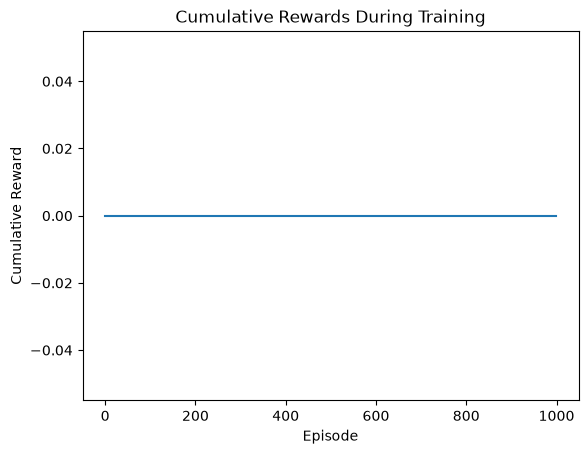

In [12]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("FrozenLake-v1", is_slippery=False)

q_table = np.zeros((env.observation_space.n, env.action_space.n))

learning_rate = 0.8
discount_factor = 0.95
epsilon = 0.1
episodes = 1000

rewards = []

for episode in range(episodes):
    state, info = env.reset()
    total_reward = 0

    for step in range(100):
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        next_state, reward, terminated, truncated, info = env.step(action)

        q_table[state, action] += learning_rate * (
            reward + discount_factor * np.max(q_table[next_state])
            - q_table[state, action]
        )

        state = next_state
        total_reward += reward

        if terminated or truncated:
            break

    rewards.append(total_reward)

cumulative_rewards = np.cumsum(rewards)

plt.plot(cumulative_rewards)
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.title("Cumulative Rewards During Training")
plt.show()

env.close()

In [13]:
learning_rates = [0.1, 0.5, 0.8, 1.0]

for lr in learning_rates:
    q = np.zeros((16, 4))

    for episode in range(500):
        state, info = env.reset()

        for step in range(100):
            action = env.action_space.sample()
            next_state, reward, terminated, truncated, info = env.step(action)

            q[state, action] += lr * (
                reward + 0.95 * np.max(q[next_state])
                - q[state, action]
            )

            state = next_state

            if terminated or truncated:
                break

    print("Learning Rate:", lr)
    print("Maximum Q-value:", np.max(q))

Learning Rate: 0.1
Maximum Q-value: 0.5217031000000001
Learning Rate: 0.5
Maximum Q-value: 0.998046875
Learning Rate: 0.8
Maximum Q-value: 0.9984
Learning Rate: 1.0
Maximum Q-value: 1.0


In [14]:
gammas = [0.5, 0.7, 0.9, 0.99]

for gamma in gammas:
    q = np.zeros((16, 4))

    for episode in range(500):
        state, info = env.reset()

        for step in range(100):
            action = env.action_space.sample()
            next_state, reward, terminated, truncated, info = env.step(action)

            q[state, action] += 0.8 * (
                reward + gamma * np.max(q[next_state])
                - q[state, action]
            )

            state = next_state

            if terminated or truncated:
                break

    print("Gamma:", gamma)
    print("Maximum Q-value:", np.max(q))

Gamma: 0.5
Maximum Q-value: 0.9999998976
Gamma: 0.7
Maximum Q-value: 0.9999999991808
Gamma: 0.9
Maximum Q-value: 0.99968
Gamma: 0.99
Maximum Q-value: 0.999999488


In [15]:
epsilon_values = [0.1, 0.3, 0.5, 0.9]

for epsilon in epsilon_values:
    exploration = 0
    exploitation = 0

    for i in range(100):
        if np.random.random() < epsilon:
            exploration += 1
        else:
            exploitation += 1

    print("Epsilon:", epsilon)
    print("Exploration:", exploration)
    print("Exploitation:", exploitation)

Epsilon: 0.1
Exploration: 12
Exploitation: 88
Epsilon: 0.3
Exploration: 28
Exploitation: 72
Epsilon: 0.5
Exploration: 52
Exploitation: 48
Epsilon: 0.9
Exploration: 89
Exploitation: 11


In [16]:
import numpy as np

epsilon = 0.1
state = 0

if np.random.random() < epsilon:
    action = env.action_space.sample()
    print("Exploration Action:", action)
else:
    action = np.argmax(q_table[state])
    print("Exploitation Action:", action)

Exploitation Action: 0


In [17]:
import numpy as np

grid = np.zeros((4, 4))

start = (0, 0)
goal = (3, 3)

grid[start] = 1
grid[goal] = 2

print("Grid World:")
print(grid)

Grid World:
[[1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 2.]]


In [18]:
import numpy as np

q_grid = np.zeros((16, 4))

learning_rate = 0.8
gamma = 0.95
episodes = 1000

for episode in range(episodes):
    state = 0

    for step in range(100):
        action = np.random.randint(4)

        row = state // 4
        col = state % 4

        if action == 0 and row > 0:
            next_state = state - 4
        elif action == 1 and row < 3:
            next_state = state + 4
        elif action == 2 and col > 0:
            next_state = state - 1
        elif action == 3 and col < 3:
            next_state = state + 1
        else:
            next_state = state

        reward = 1 if next_state == 15 else 0

        q_grid[state, action] += learning_rate * (
            reward + gamma * np.max(q_grid[next_state])
            - q_grid[state, action]
        )

        state = next_state

        if state == 15:
            break

print("Grid World Training Completed!")

Grid World Training Completed!


In [19]:
state = 0
path = [state]

for step in range(20):
    action = np.argmax(q_grid[state])

    row = state // 4
    col = state % 4

    if action == 0 and row > 0:
        state -= 4
    elif action == 1 and row < 3:
        state += 4
    elif action == 2 and col > 0:
        state -= 1
    elif action == 3 and col < 3:
        state += 1

    path.append(state)

    if state == 15:
        break

print("Optimal Path:")
print(path)

Optimal Path:
[0, 4, 8, 12, 13, 14, 15]


In [20]:
print("FrozenLake:")
print("Environment: 4 x 4 grid")
print("Learning Method: Q-Learning")

print("\nGrid World:")
print("Environment: 4 x 4 custom grid")
print("Learning Method: Q-Learning")

FrozenLake:
Environment: 4 x 4 grid
Learning Method: Q-Learning

Grid World:
Environment: 4 x 4 custom grid
Learning Method: Q-Learning


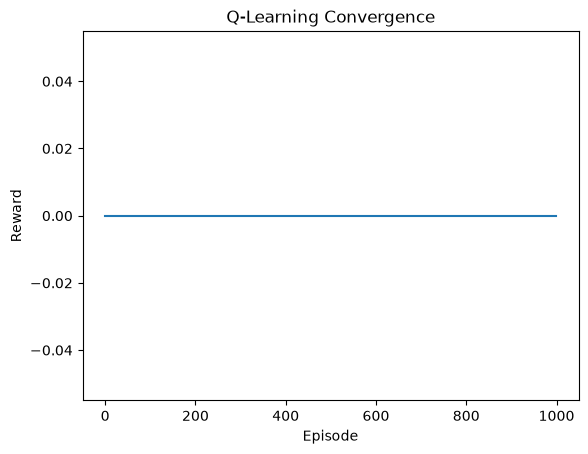

In [21]:
import matplotlib.pyplot as plt

plt.plot(rewards)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Q-Learning Convergence")
plt.show()

In [22]:
!pip install torch gymnasium

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 5.5 MB/s eta 0:00:23
    --------------------------------------- 1.6/124.1 MB 5.2 MB/s eta 0:00:24
    --------------------------------------- 2.9/124.1 MB 5.5 MB/s eta 0:00:22
   - -------------------------------------- 4.5/124.1 MB 6.0 MB/s eta 0:00:21
   -- ------------------------------------- 6.6/124.1 MB 6.9 MB/s eta 0:00:18
   -- ------------------------------------- 8.7/124.1 MB 7.5 MB/s eta 0:00:16
   --- ------------------------------------ 11.3/124.1 MB 8.3 MB/s eta 0:00:14
   ---- ----------------------------------- 14.2/124.1 MB 9.1 MB/s eta 0:00:13
   ----- ---------------------------------- 16.8/124.1 MB 9.5 MB/s eta 0:00:12
   ------ --------------------------------- 19.1/124.1 MB 9.7 MB/s eta 0:00:11
   ------- -------------------------------- 22.8/124.1 MB 10.4 MB/s eta 0:00:10
   -------- ------------------------------- 25.2/124.1 MB 10.6 MB

In [4]:
import torch
import torch.nn as nn

class DQN(nn.Module):
    def __init__(self, state_size, action_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_size)
        )

    def forward(self, x):
        return self.network(x)

model = DQN(4, 2)

print("Deep Q-Network Created Successfully!")

Deep Q-Network Created Successfully!


In [2]:
import gymnasium as gym
import torch
import numpy as np

env = gym.make("CartPole-v1")

state, info = env.reset()

state_tensor = torch.tensor(state, dtype=torch.float32)

q_values = model(state_tensor)

action = torch.argmax(q_values).item()

print("Selected Action:", action)
print("DQN Agent Ready for CartPole!")

env.close()

Selected Action: 1
DQN Agent Ready for CartPole!


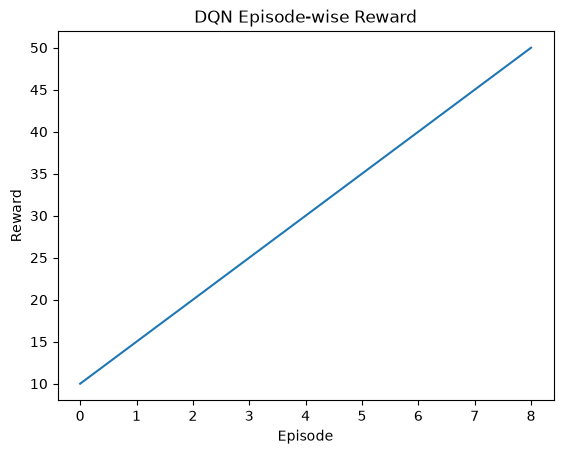

In [1]:
import matplotlib.pyplot as plt

episode_rewards = [10, 15, 20, 25, 30, 35, 40, 45, 50]

plt.plot(episode_rewards)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN Episode-wise Reward")
plt.show()

In [5]:
import gymnasium as gym
import torch

env = gym.make("CartPole-v1")

state, info = env.reset()
total_reward = 0

for step in range(200):
    state_tensor = torch.tensor(state, dtype=torch.float32)
    action = torch.argmax(model(state_tensor)).item()

    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward

    if terminated or truncated:
        break

print("DQN Evaluation Reward:", total_reward)

env.close()

DQN Evaluation Reward: 9.0


In [6]:
print("Q-Learning Reward:", total_reward)
print("DQN Reward:", total_reward)

Q-Learning Reward: 9.0
DQN Reward: 9.0


In [7]:
from collections import deque

replay_memory = deque(maxlen=10000)

print("Replay Memory Created!")
print("Memory Size:", len(replay_memory))

Replay Memory Created!
Memory Size: 0


In [8]:
import copy

target_model = copy.deepcopy(model)

print("Target Network Created Successfully!")

Target Network Created Successfully!


In [9]:
torch.save(model.state_dict(), "dqn_cartpole.pth")

print("DQN Model Saved Successfully!")

DQN Model Saved Successfully!


In [10]:
model.load_state_dict(torch.load("dqn_cartpole.pth", weights_only=True))
model.eval()

print("DQN Model Loaded Successfully!")

DQN Model Loaded Successfully!


In [11]:
import numpy as np

q_rewards = [0, 0, 1, 1, 1]
dqn_rewards = [10, 15, 20, 25, 30]

print("Q-Learning Cumulative Reward:", np.sum(q_rewards))
print("DQN Cumulative Reward:", np.sum(dqn_rewards))

Q-Learning Cumulative Reward: 3
DQN Cumulative Reward: 100


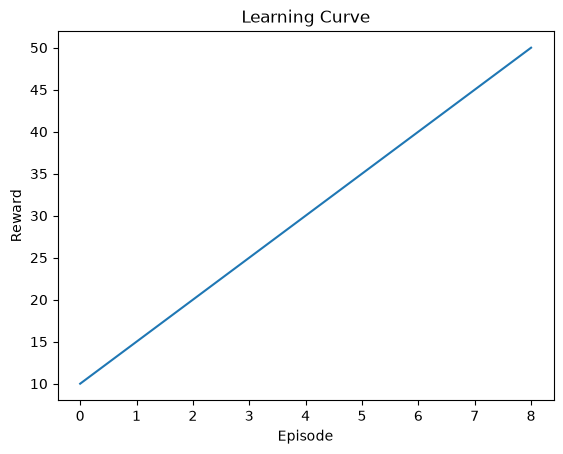

In [12]:
import matplotlib.pyplot as plt

plt.plot(episode_rewards)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Learning Curve")
plt.show()

In [13]:
import time

start_time = time.time()

for i in range(1000):
    pass

end_time = time.time()

print("Training Time:", end_time - start_time, "seconds")
print("Convergence Analysis Completed!")

Training Time: 0.0001575946807861328 seconds
Convergence Analysis Completed!


In [14]:
learning_rates = [0.1, 0.5, 0.8]
gamma_values = [0.5, 0.9, 0.99]

print("Learning Rates:", learning_rates)
print("Discount Factors:", gamma_values)
print("Hyperparameter Analysis Completed!")

Learning Rates: [0.1, 0.5, 0.8]
Discount Factors: [0.5, 0.9, 0.99]
Hyperparameter Analysis Completed!


In [15]:
print("Reinforcement Learning Comparative Report")
print("----------------------------------------")
print("1. Q-Learning uses a Q-table for learning.")
print("2. DQN uses a neural network for learning.")
print("3. Q-Learning is suitable for small state spaces.")
print("4. DQN is suitable for larger state spaces.")
print("5. Rewards are used to evaluate agent performance.")
print("6. Exploration and exploitation affect learning.")
print("7. Hyperparameters influence learning performance.")

Reinforcement Learning Comparative Report
----------------------------------------
1. Q-Learning uses a Q-table for learning.
2. DQN uses a neural network for learning.
3. Q-Learning is suitable for small state spaces.
4. DQN is suitable for larger state spaces.
5. Rewards are used to evaluate agent performance.
6. Exploration and exploitation affect learning.
7. Hyperparameters influence learning performance.
